# Before / After — 10/13 CLI(v1) vs 웹 서비스(v2)

측정 조건 (ADR-0009): 두 버전 모두 생성·라우팅 `openai:gpt-4o-mini`, 임베딩 `openai:text-embedding-3-small`, 심판 gpt-4o-mini,
테스트셋 `eval/test_cases_sample.json` 10건(express 5·answer 2·review 1·out_of_scope 2, sample_user 서류 기준), 예열 1회 후 3회 반복, 질문당 120초 제한.
v1은 10/13 그래프 원본(`skala-ai-agent/practice/dapdap`)을 그대로 호출(`eval/run_v1.py`), v2는 새 서버의 HTTP API(`eval/run_v2.py`, 자동 승인).
지표 정의는 `eval/common.py` 하나 — M1 라우팅 / M2 구조화 출력 / M3 금지 표현 / M4 개인 맥락(LLM-judge 1~5) / M5 지연.

In [1]:
import glob, json, statistics
from IPython.display import Markdown, display

def runs(pattern):
    return [json.load(open(f)) for f in sorted(glob.glob(f"eval/results/{pattern}"))]

def frac(s):
    a, b = s.split("/"); return int(a) / int(b) if int(b) else None

def mean(xs):
    xs = [x for x in xs if x is not None]; return round(statistics.mean(xs), 2) if xs else None

def agg(rs):
    S = [r["summary"] for r in rs]
    return {"반복": len(rs),
            "M1 라우팅 정확도": mean([frac(s["M1_routing"]) for s in S]),
            "M2 구조화 출력 성공률": mean([frac(s["M2_structured"]) for s in S]),
            "M3 금지 표현(최종)": mean([s["M3_banned_final"] for s in S]),
            "M4 개인 맥락(1~5)": mean([s["M4_personalization"] for s in S]),
            "M4 면접 적합(1~5)": mean([s["M4_interview_fit"] for s in S]),
            "M5 생성 평균 지연(초)": mean([s["M5_avg_seconds_generate"] for s in S]),
            "Tool 호출 수(성공 카드당)": mean([s["tool_calls_avg"] for s in S]),
            "재작성 횟수(성공 카드당)": mean([s["rewrites_avg"] for s in S]),
            "실패(오류 코드별 합)": {k: sum(t["errors"].get(k, 0) for t in S) for s in S for k in s["errors"]} or "없음"}

v1, v2 = runs("v1_test_cases_sample_r[0-9].json"), runs("v2_test_cases_sample_openai_gpt-4o-mini_r[0-9].json")
A, B = agg(v1), agg(v2)
rows = "\n".join(f"| {k} | {A[k]} | {B[k]} |" for k in A)
display(Markdown("| 지표 | v1 (10/13) | v2 (신규) |\n|---|---|---|\n" + rows))

| 지표 | v1 (10/13) | v2 (신규) |
|---|---|---|
| 반복 | 3 | 3 |
| M1 라우팅 정확도 | 0.87 | 1.0 |
| M2 구조화 출력 성공률 | 0.81 | 1.0 |
| M3 금지 표현(최종) | 0 | 0 |
| M4 개인 맥락(1~5) | 4.93 | 4.86 |
| M4 면접 적합(1~5) | 5 | 4.86 |
| M5 생성 평균 지연(초) | 13.23 | 15.26 |
| Tool 호출 수(성공 카드당) | 1.7 | 4.24 |
| 재작성 횟수(성공 카드당) | 0.7 | 1.0 |
| 실패(오류 코드별 합) | {'OpenAIInvalidRequestError': 1, 'TIMEOUT': 3} | 없음 |

In [2]:
def status(r):
    return "✅" if r.get("structured_ok") or (r["expected"] not in ("express", "answer") and r.get("intent") == r["expected"]) \
        else (r.get("error") or f"오분류:{r.get('intent')}")

ids = [r["id"] for r in v2[0]["rows"]]
lines = ["| 케이스 | 입력 | v1 (회차별) | v2 (회차별) |", "|---|---|---|---|"]
for i, cid in enumerate(ids):
    lines.append(f"| {cid} | {v2[0]['rows'][i]['input'][:28]} | {' · '.join(status(x['rows'][i]) for x in v1)} | "
                 f"{' · '.join(status(x['rows'][i]) for x in v2)} |")
display(Markdown("\n".join(lines)))

| 케이스 | 입력 | v1 (회차별) | v2 (회차별) |
|---|---|---|---|
| S01 | 고객 이탈을 미리 예측하는 모델을 만들었어요 | ✅ · OpenAIInvalidRequestError · TIMEOUT | ✅ · ✅ · ✅ |
| S02 | 처음엔 정확도만 봤는데 쿠폰 비용까지 함께 보도록  | ✅ · ✅ · ✅ | ✅ · ✅ · ✅ |
| S03 | 배송 지연의 61%가 특정 택배사의 집하 구간에 몰 | ✅ · TIMEOUT · ✅ | ✅ · ✅ · ✅ |
| S04 | 두 달 사이 변화라 계절 요인은 완전히 배제하지 못 | ✅ · ✅ · ✅ | ✅ · ✅ · ✅ |
| S05 | 분석 결과를 운영 팀장님이 매주 볼 수 있게 대시보 | ✅ · ✅ · ✅ | ✅ · ✅ · ✅ |
| S06 | Could you briefly introduce  | ✅ · ✅ · ✅ | ✅ · ✅ · ✅ |
| S07 | 면접 질문: 분석 결과가 현업의 예상과 다를 때 어 | ✅ · ✅ · TIMEOUT | ✅ · ✅ · ✅ |
| S08 | 오늘 복습할 카드 보여줘 | ✅ · ✅ · ✅ | ✅ · ✅ · ✅ |
| S09 | 오늘 점심 메뉴 추천해줘 | ✅ · ✅ · ✅ | ✅ · ✅ · ✅ |
| S10 | 파이썬으로 YOLO 학습 코드 짜줘 | ✅ · ✅ · ✅ | ✅ · ✅ · ✅ |

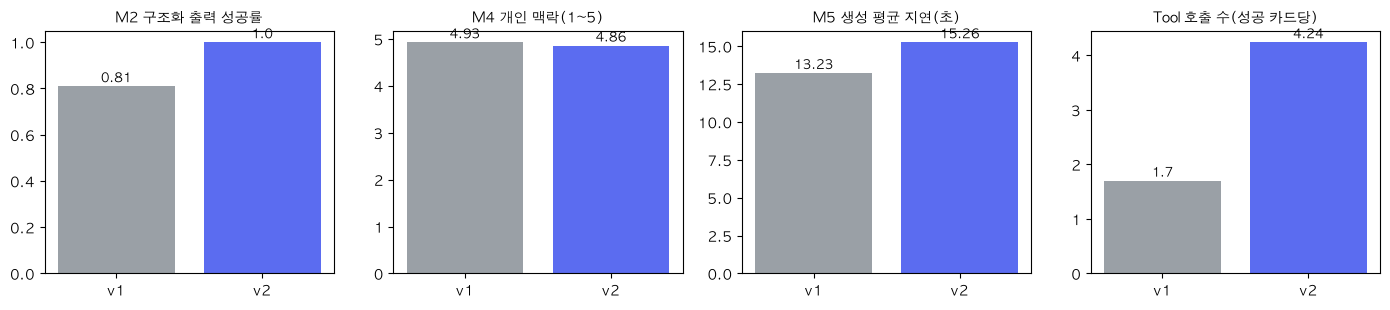

In [3]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = ["AppleGothic", "sans-serif"]
keys = ["M2 구조화 출력 성공률", "M4 개인 맥락(1~5)", "M5 생성 평균 지연(초)", "Tool 호출 수(성공 카드당)"]
fig, axes = plt.subplots(1, len(keys), figsize=(14, 3.2))
for ax, k in zip(axes, keys):
    vals = [A[k] or 0, B[k] or 0]
    ax.bar(["v1", "v2"], vals, color=["#9aa0a6", "#5b6cf0"])
    ax.set_title(k, fontsize=10)
    for x, v in enumerate(vals):
        ax.text(x, v, f"{v}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

In [4]:
x = json.load(open("eval/results/extras.json"))
display(Markdown(f"""| 지표 (design §7) | v1 (10/13) | v2 (신규) | 근거 |
|---|---|---|---|
| 재시작 후 승인 대기 복원 | 0/3 (구조상) | {x['restart_restored']} | v1은 InMemorySaver(프로세스 메모리), v2는 AsyncSqliteSaver(checkpoints.db) |
| 2요청 처리 총 시간 | 순차만 가능(동기 CLI) | 순차 {x['sequential_2_seconds']}초 → 동시 {x['concurrent_2_seconds']}초 | 모든 노드 async (ADR-0005) |
| MCP stdio 오버헤드 (한계 1) | 해당 없음(직접 호출) | 호출당 {x['mcp']['mcp_overhead_ms']}ms (직접 {x['mcp']['direct_ms']}ms → MCP {x['mcp']['mcp_ms_median']}ms) | fake 임베딩으로 네트워크 제외, {x['mcp']['calls']}회 중앙값 |
| 체크포인트 DB 크기 (한계 2) | 해당 없음 | 대화당 약 {x['checkpoint_bytes_per_conversation'] // 1024}KB ({x['conversations']}개 대화 {x['checkpoint_db_bytes'] // 1024}KB) | 승인 대기 복원의 대가 |"""))

| 지표 (design §7) | v1 (10/13) | v2 (신규) | 근거 |
|---|---|---|---|
| 재시작 후 승인 대기 복원 | 0/3 (구조상) | 3/3 | v1은 InMemorySaver(프로세스 메모리), v2는 AsyncSqliteSaver(checkpoints.db) |
| 2요청 처리 총 시간 | 순차만 가능(동기 CLI) | 순차 28.4초 → 동시 14.5초 | 모든 노드 async (ADR-0005) |
| MCP stdio 오버헤드 (한계 1) | 해당 없음(직접 호출) | 호출당 1.0ms (직접 0.04ms → MCP 1.04ms) | fake 임베딩으로 네트워크 제외, 20회 중앙값 |
| 체크포인트 DB 크기 (한계 2) | 해당 없음 | 대화당 약 121KB (8개 대화 968KB) | 승인 대기 복원의 대가 |

In [5]:
import os
lines = ["| 모델 (v2, sample 10건) | M2 구조화 출력 | 실패 코드 | 생성 평균 지연(초) |", "|---|---|---|---|"]
for f in sorted(glob.glob("eval/results/v2_test_cases_sample_*_r[a-z0-9]*.json")):
    d = json.load(open(f)); s = d["summary"]
    if "ollama" in d["model"] or f.endswith("_r1.json"):
        lines.append(f"| {d['model']} | {s['M2_structured']} | {s['errors'] or '-'} | {s['M5_avg_seconds_generate']} |")
display(Markdown("한계 3 — 소형 로컬 모델의 구조화 출력 실패율\n\n" + "\n".join(lines)))

한계 3 — 소형 로컬 모델의 구조화 출력 실패율

| 모델 (v2, sample 10건) | M2 구조화 출력 | 실패 코드 | 생성 평균 지연(초) |
|---|---|---|---|
| ollama:qwen3.5:4b | 5/7 | - | 359.32 |
| ollama:qwen3:8b | 0/7 | {'LLM_OUTPUT_INVALID': 6} | None |
| openai:gpt-4o-mini | 7/7 | - | 16.94 |

In [6]:
r1, r2 = runs("v1_test_cases_rref.json"), runs("v2_test_cases_openai_gpt-4o-mini_rref.json")
if r1 and r2:
    a, b = agg(r1), agg(r2)
    display(Markdown("참고: 기존 테스트셋 10건(실제 사용자 경력 전제 문장, sample 서류로 실행 — 개인 맥락 점수 해석 주의)\n\n"
                     "| 지표 | v1 | v2 |\n|---|---|---|\n" + "\n".join(f"| {k} | {a[k]} | {b[k]} |" for k in a)))

참고: 기존 테스트셋 10건(실제 사용자 경력 전제 문장, sample 서류로 실행 — 개인 맥락 점수 해석 주의)

| 지표 | v1 | v2 |
|---|---|---|
| 반복 | 1 | 1 |
| M1 라우팅 정확도 | 1.0 | 1.0 |
| M2 구조화 출력 성공률 | 1.0 | 1.0 |
| M3 금지 표현(최종) | 0 | 0 |
| M4 개인 맥락(1~5) | 4.71 | 4.14 |
| M4 면접 적합(1~5) | 4.86 | 4.71 |
| M5 생성 평균 지연(초) | 14.21 | 15.0 |
| Tool 호출 수(성공 카드당) | 1.86 | 4.71 |
| 재작성 횟수(성공 카드당) | 0.86 | 1.29 |
| 실패(오류 코드별 합) | 없음 | 없음 |

## 가설(design §7) vs 실측 — 해석

| 지표 | 가설 | 실측 | 판정 |
|---|---|---|---|
| 라우팅·구조화 출력·LLM-judge | 비슷 (기능 후퇴 없음) | 라우팅 v1 26/30 → v2 30/30, 카드 생성 v1 17/21 → v2 21/21, 개인 맥락 둘 다 약 4.9 | 후퇴 없음 + **실패 제거** |
| Tool 호출 수·재작성 | 비교 | 카드당 검색 v1 약 1.7 → v2 약 4.2, 재작성 약 0.7 → 약 1.0 | 독립 Reviewer(MCP Prompt 규칙)가 더 자주 되돌려 보냄 |
| 재시작 후 승인 대기 복원 | 0/N → N/N | 0/3(구조상) → 3/3 | 확인 |
| 동시 2요청 | 순차 → 병행 | 28.4초 → 14.5초 | 확인 (async) |
| 1건 평균 지연 | 증가 가능 | 성공 카드 기준 v1 약 13초 → v2 약 15초 | 증가 (한계로 보고) |

**v1 실패의 정체**: 10/13 그래프의 `ToolCallLimitMiddleware(run_limit=4)`가 카드 출력 호출까지 막아, gpt-4o-mini가 검색을 많이 하면 무한 반복(TIMEOUT) 또는 OpenAI 400(tool 메시지 순서)으로 끝났다. 10/13 당시 기본 모델(Gemini)에서는 드러나지 않았다. v2는 검색 상한에 닿으면 검색 Tool을 숨겨 카드 출력만 남기는 방식(ADR-0021)으로 고쳤다.

## 한계 4종 (실측)
1. **MCP stdio 오버헤드** — 호출당 약 1ms. 카드 1장에 검색 약 4회라 지연 증가의 주원인은 아니다(주원인은 검색·재작성 횟수 증가).
2. **체크포인트 DB 증가** — 대화당 약 121KB. 1,000건이면 약 120MB로, 정리 정책(오래된 thread 삭제)이 필요하다.
3. **소형 로컬 모델의 구조화 출력** — 같은 10건에서 gpt-4o-mini 7/7, qwen3.5:4b 5/7(라우팅 오분류 2건, 1건 28분 지연), qwen3:8b 0/7. 개인정보를 위해 ollama를 고르면 품질·응답 시간을 잃는다. thinking 모드는 끄고 쓴다(ADR-0020).
4. **단일 사용자 + 외부 LLM 전송** — SQLite 파일 잠금 때문에 다중 인스턴스 공유가 안 되고(강의 p.21은 PostgreSQL 채택), OpenAI를 쓰면 서류가 외부로 전송된다(준비 점검이 경고).

추가로 관찰한 한계: 서버를 켠 뒤 첫 요청은 색인 준비로 약 70초 걸린다(측정은 예열로 제외). 표본이 10건×3회라 통계적 유의성은 약하다.